In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import glob
file = glob.glob("*.csv")[0]
df = pd.read_csv(file, encoding = "latin1")
print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
print("Datset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDatset Information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())


Datset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Datset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal

In [4]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [7]:
category_analysis = df.groupby("Category")[["Sales", "Profit"]].sum()
print(category_analysis)

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


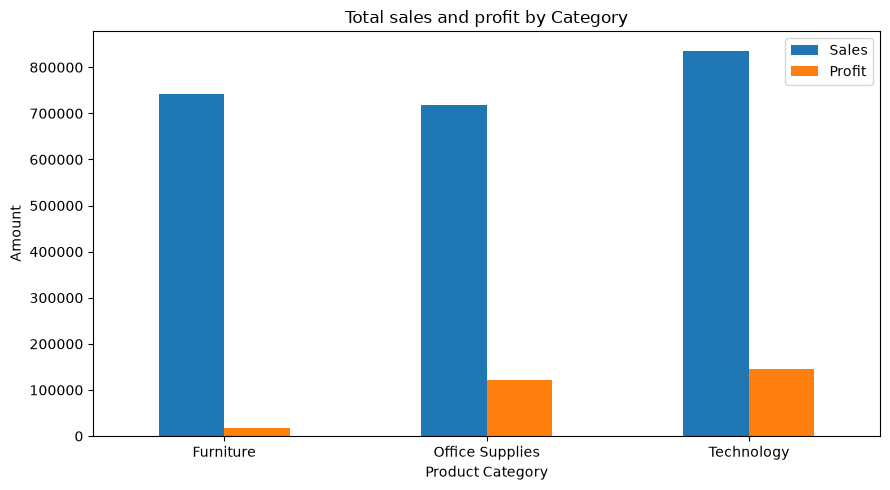

In [8]:
category_analysis.plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Total sales and profit by Category")
plt.xlabel("Product Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region_analysis)

               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


In [11]:
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()
print(correlation[["Sales", "Profit", "Discount", "Quantity"]])

                Sales    Profit  Discount  Quantity
Row ID      -0.001359  0.012497  0.013480 -0.004016
Postal Code -0.023854 -0.029961  0.058443  0.012761
Sales        1.000000  0.479064 -0.028190  0.200795
Quantity     0.200795  0.066253  0.008623  1.000000
Discount    -0.028190 -0.219487  1.000000  0.008623
Profit       0.479064  1.000000 -0.219487  0.066253


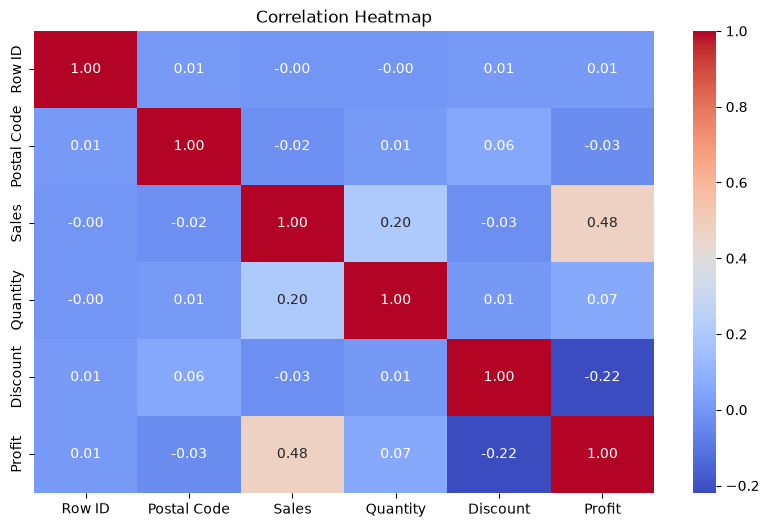

In [12]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout
plt.show()

In [13]:
print("EDA KEY INSIGHTS")
print("-----------------")
print("1. Technology has the highest total sales and profit.")
print("2. The west region has the highest total profit.")
print("3. Sales and profit have a moderate positive correlation.")
print("4. Discount and profit have a negative correlation.")

EDA KEY INSIGHTS
-----------------
1. Technology has the highest total sales and profit.
2. The west region has the highest total profit.
3. Sales and profit have a moderate positive correlation.
4. Discount and profit have a negative correlation.


# Conclusion

- The dataset contains 9,994 records and 21 columns.
- No missing values or duplicate rows were found.
- Technology generated the highest total sales and profit among the three product categories.
- The west region recorded the highest total profit.
- Sales nad profit showed a moderate positive correlation.
- Discount and profit showed a negative correlation.

This EDA project helped identify important patterns and relationships in the e-commerce dataset using Python, Pandas, matplotlib, and Seaborn.